# Learning and Training

> #### AI usage disclaimer
> I used an AI agent to help create the training script callbacks (detailed below), based on what I wanted as behavior.  
> There are no statements made by the AI, but an AI agent has reviewed this notebook and helped me make it more readable.

At this point we have everything in place to begin training.

I've chosen to use Stable Baselines3 - I've hinted at it with a video in the second notebook ([Custom Environments - Reinforcement Learning with Stable Baselines 3 (P.3)](https://inv.nadeko.net/watch?v=uKnjGn8fF70&listen=false)).

The reason for choosing it is simplicity. It handles training, saving models, loading models very well internally while also exposing an API that's nice to work with and has sensible defaults. It's really geared towards Gymnasium environments so it makes sense to use it for our target.

## The training script

I've started the training script with something really simple, a copy of the environment presented in [Custom Environments - Reinforcement Learning with Stable Baselines 3 (P.3)](https://inv.nadeko.net/watch?v=uKnjGn8fF70&listen=false).  
It's also available here in text format: [Reinforcement Learning in Python with Stable Baselines 3](https://pythonprogramming.net/saving-and-loading-reinforcement-learning-stable-baselines-3-tutorial/)

The tutorial already goes through the basics, I highly recommend it as it helped me the most to get started out of all the resources I stumbled on.
I won't reiterate what's stated there, but it's important to mention that tensorboard was also set up and PPO was also used. PPO wasn't really chosen at this point, I wanted to just get started and see what works and how well it works. My approach is to write these notebooks just as I learn (no more than a few days after reaching any milestone), which is why it probably isn't for you if you already know how all of this is done.

I've also added three callbacks to the script (with the help of an AI agent), each addressing a gap I noticed while training:

1. **Saving the best model.**  
I've noticed a comment from a Stable Baselines 3 maintainer mentioning that there's an EvalCallback which can help to save the best model from a training round, so I added it to the training script.

2. **Saving on interrupt.**  
I've interrupted training while tweaking the reward function (detailed in the Reward function tweaks section below) and I noticed I would be cutting timesteps (progress or number of experiences) when resuming, because often the best performance was earlier (even much earlier) throughout the model's progression. To deal with this I asked the AI agent to add a new callback that saves the latest model when the script is interrupted (CTRL+C), so progress made since the last best-model save isn't lost.

3. **Logging reward components.**  
The environment reports each reward term it computed for the step (drift, damage, progress) in its `info`, and the callback writes them out as `reward/*` scalars - so you can see *why* the total reward moves, not just that it moved.

4. **Logging BEV maps.**  
The environment saves BEV maps when the reset function is called - before the car is replaced and afterwards, resulting in maps usually showing crashes and maps showing an initial spawn point. These are unused for now, visible in the tensorboard interface, but I added this logging thinking that in the future I might want to test the CNN against these maps, to visualize how it works.

## Additions to the environment

The environment went through a few changes while training:

1. **Recovering from deadlocks and crashes**  
The environment sometimes made the game deadlock or crash and dump traces. It became relevant to keep the training process alive while recovering the game, and this is now done in the reset function.

2. **The car shown in the BEV center**  
The BEV now contains a representation of the car, correctly aligned based on the drift angle. I consider the drift angle important, so both the BEV and the separate float input seem like a design choice that should help the neural network. The space in the center was dead otherwise, with just a few car points being caught by the LiDAR which weren't consistent, so if those appeared anyway I wanted them to be more consistent.

3. **A spawn system that keeps progress**  
I designed a spawn system that kept the car's last undamaged progress as a spawn point for the next reset - once the car was stuck against a barrier, it had to overcome it rather than landing in a totally new environment. Eval-stage resets are also detected, and when one occurs a random map waypoint is chosen.

4. **A flat action space**  
The action space was a `spaces.Dict` wrapping a single `controls` key (notebook 02 still describes it that way). A Dict with one Box inside doesn't buy anything, so I flattened it to a plain `spaces.Box` of the three values `[steering, throttle/brake, parkingbrake]`; `step()`, the benchmark and the tests now unpack the array directly.

Other changes include reward tweaks, detailed in the Reward function tweaks section below.

## What I learned as the model learned

### How the model behaved

> Note: the graphs below were reproduced for your convenience, but normally when training you should launch tensorboard (`tensorboard --logdir="logs"`) and see them in a browser (http://localhost:6006/).  
> [Using tensorboard via jupyter notebooks](https://www.tensorflow.org/tensorboard/tensorboard_in_notebooks) is also possible but it wasn't done here because the logs here weren't committed.

The model's behavior went through several stages, each one revealing a new limitation:

1. **Reverse driving** - timesteps `0 -> ~5000`  
At the very beginning, the model liked to just drive in reverse.

2. **Always forwards, even into a wall** - timesteps `~5000 -> ~350000`  
At some point it learned to always drive forwards, even if into a wall. Even 300k timesteps into training this did not change - I never observed the model reversing again.

3. **Stuck against obstacles** - timesteps `0 -> ~350000`  
Sometimes, when the episode wasn't ending due to a crash, the agent was constantly spinning wheels against a barrier, moving nowhere. The length and reward graphs show that - when the episode length is high usually the reward isn't rising by too much if at all.

4. **The policy converged** - timesteps `0 -> ~350000`  
In tensorboard this shows up as a nearly flat reward curve: `eval/mean_reward` - the average below barely improves near the end, which matches what I was seeing in the game: the policy found an "exploit" - ocasionally doing donuts.

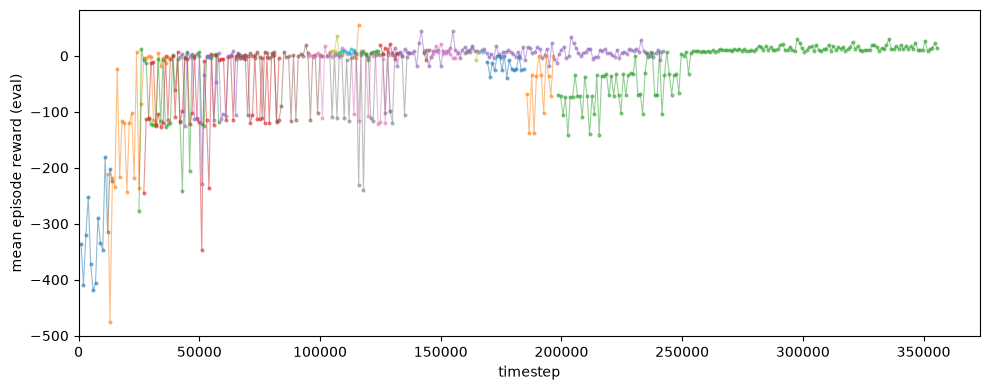

In [7]:
# average reward over timesteps, from the tensorboard event files in
# logs-bak - the same data the `tensorboard` UI renders, plotted here so the
# notebook stays self-contained
import glob

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

LOG_ROOT = "drift-ai/logs-bak/PPO"

fig, ax = plt.subplots(figsize=(10, 4))
for run_dir in sorted(glob.glob(f"{LOG_ROOT}/*/PPO_*")):
    ea = EventAccumulator(run_dir)
    ea.Reload()
    if "eval/mean_reward" not in ea.Tags()["scalars"]:
        continue
    events = ea.Scalars("eval/mean_reward")
    ax.plot([e.step for e in events], [e.value for e in events],
            lw=0.8, alpha=0.5, marker="o", ms=2)
ax.set_xlim(0, None)
ax.set_xlabel("timestep")
ax.set_ylabel("mean episode reward (eval)")
plt.tight_layout()
plt.show()


5. **Crashing earlier and earlier** - timesteps `0 -> ~180000` and timesteps `180000 -> ~250000`  
Because of increased speed and no improvement in obstacle detection, the car crashed earlier and earlier - this is also visible in tensorboard: `eval/mean_ep_length`. Past the timestep `250k` is where I changed the spawn to be fixed, with an obstacle straight ahead.  
The episode length seems like it's improving overall but in fact it only learned to always hold the gas and the steering fully to the right, and with random cars there was just one that did donuts, which is what increased the episode length (it crashed later than the rest of the cars).

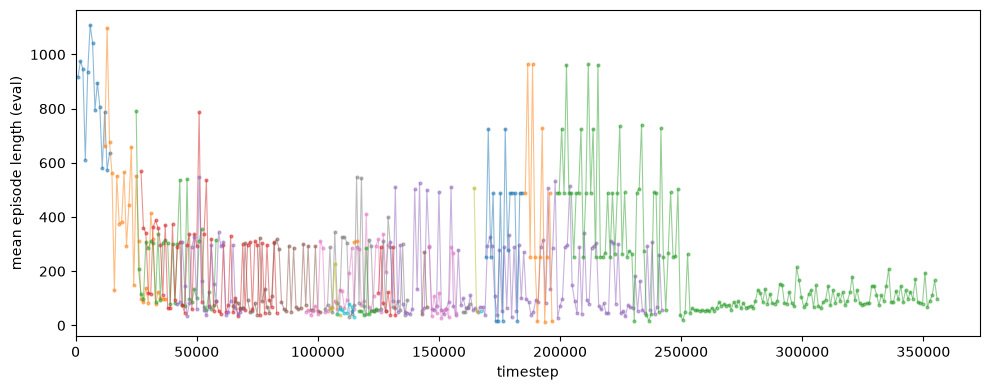

In [8]:
# same, for the mean episode length - the car crashing earlier and earlier
import glob

import matplotlib.pyplot as plt
%matplotlib inline
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

fig, ax = plt.subplots(figsize=(10, 4))
for run_dir in sorted(glob.glob(f"{LOG_ROOT}/*/PPO_*")):
    ea = EventAccumulator(run_dir)
    ea.Reload()
    if "eval/mean_ep_length" not in ea.Tags()["scalars"]:
        continue
    events = ea.Scalars("eval/mean_ep_length")
    ax.plot([e.step for e in events], [e.value for e in events],
            lw=0.8, alpha=0.5, marker="o", ms=2)
ax.set_xlim(0, None)
ax.set_xlabel("timestep")
ax.set_ylabel("mean episode length (eval)")
plt.tight_layout()
plt.show()


What all of this hinted at is that the model isn't locating obstacles and it can't learn how to avoid obstacles (at least not efficiently), and that it converges on certain behaviours and never seems to correct them.

### Reward function tweaks

The reward function went through several iterations, each responding to a behavior the model had converged on:

1. **Reward forward motion only.**  
At the start the model was always driving in reverse, so I rewarded only forwards movement. It learned to drive forwards.

2. **Full throttle stuck.**  
The model was afterwards always driving full throttle - this behavior never really changed, even though I later only rewarded speed, ignoring direction.

3. **A wall ahead, to force observation.**  
I tried to encourage the model to observe the environment; it seemed that the random spawn points were not helping it understand, so I always spawned it with a wall directly ahead (visible in the episode-length plot above - it starts varying less around 250k timesteps). From this it learned to go full throttle and steer right, and with random cars it sometimes got one that could do donuts without hitting the opposite barrier - rewarded without merit, not really drifting like I hoped.

4. **Spawn against the obstacle.**  
Another change to the spawn system: once the car got stuck against an obstacle, it would be spawned against it again, encouraging a learning path that handles various new obstacles. Eval resets still move to a random map waypoint, just to ensure a clean starting point once in a while.

5. **Distance traveled instead of speed.**  
I moved from rewarding speed to rewarding distance traveled between steps - nearly the same, but with an embedded negative component when the car is detected as not progressing fast enough. The distance is also checked over a rolling window of 15 seconds and can end the episode earlier when stalling is detected.

### What's missing

At this point (when this notebook is committed) it became clear to me that this setup is probably never going to learn to drift. Throughout all of the iterations in the environment, it would find what would appear as a very simplistic strategy and would repeat it seemingly endlessly, and this impression is accentuated by how slow training goes with BeamNG.tech - timesteps are difficult to process.

To understand where we went wrong we have to [understand PPO](https://spinningup.openai.com/en/latest/algorithms/ppo.html#background), Stable Baselines3 and Reinforcement Learning overall, at least in basic terms.

### Understanding Reinforcement Learning (RL) practically
> General remark: when a link is given that's part of a training series, I recommend going through it fully.  
> This section is mostly meant as a guided introduction, just for your orientation, and is focused to the BeamNG.tech environment which is continuous (in the observation and action spaces) and overall non-deterministic.

We chose `PPO` as the training algorithm without really understanding Reinforcement Learning yet or what's available for us to use to reach our target - drifting in BeamNG.tech.

Another set of implicit choices shaped the setup - the kind of algorithm (`Model-Free`, `On-Policy`) and the policy network (`MultiInputPolicy`, a SB3 term) - which we'll have to expose and detail, to better understand what went wrong.

I recommend re-visiting the description of the environment at the start of notebook 02 before continuing, I'll be using terms from there which are important to know as context here.

#### RL Policy

A policy is a rule used by an agent to decide what actions to take in order to maximize reward. You can also think of it as the neural network or a virtual brain.  
This brain or policy is parametrized which makes it adjustable. The two most important aspects of this policy are how the neurons are arranged (the network) and what the parameters are - the weights and biases which describe each neuron.

This policy - its neurons / parameters - are constantly adjusted during training so it takes actions that maximize reward. This is what reinforcement learning essentially means.

The policy which we've detailed so far is referring solely to the agent - the actor in the environment. This is the classical meaning of the term, but it's sometimes also used to describe the method of updating the agent / brain during the training phase.

#### PPO

Proximal Policy Optimization (`PPO`) is described by [OpenAI](https://spinningup.openai.com/en/latest/algorithms/ppo.html#background) as a family of training algorithms optimized for taking the biggest possible improvement step on a policy "without stepping so far that we accidentally cause performance collapse.".

In other words, `PPO` is focused on keeping the new, adjusted policy in close proximity to the previous policy in the learning process, based on [the intuition](https://huggingface.co/learn/deep-rl-course/unit8/intuition-behind-ppo) that smaller adjustments to parameters will lead to more precise policy updates which could then lead to the best possible policy. In reality we've seen that it can also lead to converging on a policy that isn't adjusted to a complex environment, however to be fair there were some other quality degrading choices which mean we can't blame `PPO` entirely.

The same [Spinning Up page](https://spinningup.openai.com/en/latest/algorithms/ppo.html#quick-facts) notes, under its Quick Facts, that `PPO` is `On-Policy`. What this means is that the policy used for learning is the same one the agent uses to act in the environment. 

The [On-Policy](https://en.wikipedia.org/wiki/Reinforcement_learning#Comparison_of_key_algorithms) RL algorithms perform policy updates using [trajectories](https://spinningup.openai.com/en/latest/spinningup/rl_intro.html?highlight=trajectories#trajectories) (a sequence of states and actions in the environment) obtained from the current policy, which means that each update only uses data collected while acting according to the most recent version of the policy.    
In contrast, `Off-Policy` RL algorithms separate the policy the agent follows to act and explore - the `behavior policy` - from the one actually being optimized, the `target policy`. The `target policy` is updated from trajectories the `behavior policy` collected, which means that each update can use trajectories collected at any point during training, regardless of how the agent was choosing to explore the environment when the data was obtained ([What to Learn in Model-Free RL](https://spinningup.openai.com/en/latest/spinningup/rl_intro2.html#what-to-learn-in-model-free-rl)). (In the actor-critic variants we'll consider, a separate value function - the critic - is what estimates the likely reward.)

It becomes evident that an `Off-Policy` RL algorithm would likely be more sample-efficient, because it can reuse previous experiences to keep updating the `target policy`, instead of being limited to the data the current policy just collected.

#### RL Algorithms

There's a nice graph of the [different kinds of RL algorithms](https://spinningup.openai.com/en/latest/spinningup/rl_intro2.html) (non-exhaustive) which you'll immediately notice being split into two main categories: `Model-Free` and `Model-Based`.

Models in this sense refer to a close replica of an environment, like a simulation. An example would be the BeamNG physics engine which tries to replicate how different materials interact and deform, based on actual physics.

##### Model-Free

A `Model-Free` algorithm doesn't use a model of the environment at all - it learns to act purely from the experience of interacting with it. It doesn't exploit the potential sample-efficiency gains a model could bring, but tends to be easier to implement and tune, and (per the linked article) is the more popular and more extensively tested family. Both `PPO` and the off-policy alternatives we'll consider are model-free.

##### Model-Based

A `Model-Based` algorithm has access to - or learns - a **model of the environment**: a function that predicts state transitions and rewards. The upside is that it lets the agent **plan** by thinking ahead and seeing what would happen for a range of choices before committing (a famous example is AlphaZero), which can substantially improve sample efficiency. The downside is that a ground-truth model is usually not available, so the agent has to learn it from experience - and bias in that learned model can be *exploited* by the agent, so it performs well with respect to the model but sub-optimally in the real environment. Model-learning is fundamentally hard.

Why we made the `Model-Free` choice: we already have a high-fidelity simulator (BeamNG.tech) to interact with, and learning a separate model of the car's dynamics on top of that would add a hard, bias-prone learning problem without an obvious payoff. We could also try to adopt the game's own physics engine as a model, but this would be just as hard. So we learn the policy directly from interaction - model-free - and accept the sample-efficiency cost.


#### Policy Networks of SB3

[Stable Baselines3 Policy Networks Docs](https://stable-baselines3.readthedocs.io/en/v2.9.0/guide/custom_policy.html) can be a good starting point to understand the policy we've chosen (`MultiInputPolicy`), we can see it mentioned in the first sentence there: 
> Stable Baselines3 provides policy networks for images (CnnPolicies), other type of input features (MlpPolicies) and multiple different inputs (`MultiInputPolicies`).

Reading further on that page, a SB3 policy network is split into two parts:

- A **features extractor** (front-end) whose job is to turn the raw observation into a single feature vector - for an image that's a CNN, for a plain vector it's just a flatten. This is the `features_extractor_class` parameter.
- A **fully-connected network** (back-end) that maps that feature vector to the action and the value estimate. Its size is the `net_arch` parameter.

Our observation space is made up of two very different kinds of inputs:

- **Low-dimensional vectors** - rpm, IMU acceleration and angular velocity, drift angle, airspeed, is-shifting. These are just a short list of numbers with no spatial structure, so a plain fully-connected network handles them fine.
- **The BEV** - a `(64, 64)` grid where each cell holds the highest LiDAR return in that area (road ~ 0.5, the car's own footprint painted as a solid block). This is a *spatial* input: neighboring cells are related, an obstacle is a connected blob, a road edge is a line.

`MultiInputPolicy` is the variant for our case - a `Dict` observation space with several different inputs. By default it uses a `CombinedExtractor`: for each key it [runs a CNN if the key looks like an image](https://stable-baselines3.readthedocs.io/en/v2.9.0/guide/custom_policy.html#sb3-policy), otherwise it just flattens it, then concatenates all the results into one vector for the back-end.

To check if the `BEV` was flattened, let's print the network SB3 actually built for our observation space. The next cell reconstructs the same `MultiInputPolicy` that `train.py` uses - default settings, no custom features extractor - and prints its architecture.

In [2]:
# Show the network SB3 actually builds for our observation space with the
# default MultiInputPolicy - the point is to see what happens to the BEV.
import numpy as np
import gymnasium as gym
from stable_baselines3.ppo import MultiInputPolicy

BEV_N = 64
# Mirrors the env's observation space (see notebook 02 / beamng_tech.py)
obs_space = gym.spaces.Dict({
    "rpm":         gym.spaces.Box(0.0, 1.0, (1,), np.float32),
    "imu_acc":     gym.spaces.Box(-1.0, 1.0, (3,), np.float32),
    "imu_angvel":  gym.spaces.Box(-1.0, 1.0, (3,), np.float32),
    "drift_angle": gym.spaces.Box(-1.0, 1.0, (1,), np.float32),
    "airspeed":    gym.spaces.Box(0.0, 1.0, (1,), np.float32),
    "is_shifting": gym.spaces.Box(0.0, 1.0, (1,), np.float32),
    "bev":         gym.spaces.Box(0.0, 1.0, (BEV_N, BEV_N), np.float32),
})
act_space = gym.spaces.Box(low=np.array([-1.0, -1.0, -1.0], np.float32),
                           high=np.array([1.0, 1.0, 1.0], np.float32))

# Default policy - no custom features extractor, exactly what train.py uses
policy = MultiInputPolicy(obs_space, act_space, lr_schedule=lambda x: 3e-4)

print(policy)

MultiInputActorCriticPolicy(
  (features_extractor): CombinedExtractor(
    (extractors): ModuleDict(
      (airspeed): Flatten(start_dim=1, end_dim=-1)
      (bev): Flatten(start_dim=1, end_dim=-1)
      (drift_angle): Flatten(start_dim=1, end_dim=-1)
      (imu_acc): Flatten(start_dim=1, end_dim=-1)
      (imu_angvel): Flatten(start_dim=1, end_dim=-1)
      (is_shifting): Flatten(start_dim=1, end_dim=-1)
      (rpm): Flatten(start_dim=1, end_dim=-1)
    )
  )
  (pi_features_extractor): CombinedExtractor(
    (extractors): ModuleDict(
      (airspeed): Flatten(start_dim=1, end_dim=-1)
      (bev): Flatten(start_dim=1, end_dim=-1)
      (drift_angle): Flatten(start_dim=1, end_dim=-1)
      (imu_acc): Flatten(start_dim=1, end_dim=-1)
      (imu_angvel): Flatten(start_dim=1, end_dim=-1)
      (is_shifting): Flatten(start_dim=1, end_dim=-1)
      (rpm): Flatten(start_dim=1, end_dim=-1)
    )
  )
  (vf_features_extractor): CombinedExtractor(
    (extractors): ModuleDict(
      (airspeed): 

Reading the output, two things stand out:

- The `features_extractor` is a `CombinedExtractor`, and every key - **including `bev`** - is just a `Flatten` layer. There is no CNN anywhere in the front-end.
- The back-end shows the consequence: `policy_net` and `value_net` both begin with `Linear(in_features=4106, ...)`. That 4106 is exactly the 4096 flattened BEV values concatenated with the 10 low-dim channels.

The default `CombinedExtractor` doesn't run a CNN on the BEV - it **flattens** the 4096 values and feeds them as a vector into the fully-connected back-end, destroying the spatial information of the grid.

The decision of whether a key gets a CNN or a flatten is made by a single function, `is_image_space` - if it returns `True` the key is treated as an image and run through a `NatureCNN`, otherwise it's just flattened. Let's print its source to see exactly what it checks.

In [6]:
# The function that decides, for each observation key, whether SB3 treats it as an image (-> CNN) or as a plain vector (-> flatten).
from stable_baselines3.common.preprocessing import is_image_space

?is_image_space

Signature:
is_image_space(
    observation_space: gymnasium.spaces.space.Space,
    check_channels: bool = False,
    normalized_image: bool = False,
) -> bool
Docstring:
Check if a observation space has the shape, limits and dtype
of a valid image.
The check is conservative, so that it returns False if there is a doubt.

Valid images: RGB, RGBD, GrayScale with values in [0, 255]

:param observation_space:
:param check_channels: Whether to do or not the check for the number of channels.
    e.g., with frame-stacking, the observation space may have more channels than expected.
:param normalized_image: Whether to assume that the image is already normalized
    or not (this disables dtype and bounds checks): when True, it only checks that
    the space is a Box and has 3 dimensions.
    Otherwise, it checks that it has expected dtype (uint8) and bounds (values in [0, 255]).
:return:
File:      ~/Projects/beamng-drift-project/venv/lib/python3.14/site-packages/stable_baselines3/common/prepr

You'll notice that this also accepts grayscale - which matches roughly the definition of our BEV, however it's considering just `uint8`: `[0, 255]`, and because our BEV has `float` values in the range `[0, 1]` this function judges that it isn't an image.

For spatial input like the BEV, a plain fully-connected network (which is what the default `CombinedExtractor` gives us, since it flattens the grid) has to re-learn "what an obstacle looks like" separately for every position on the map, or it may simply learn to ignore most points. 

A **Convolutional Neural Network (CNN)** is built to make learning patterns easier: it uses small filters that slide across the grid and are reused at every position, so it learns a pattern like "obstacle ahead" or "right turn" once and finds it easily afterwards. The `(64, 64)` grid is reduced to a set of filters applied over regions of the grid which abstract away the complexity, providing information that is more dense and actionable.  [Convolutions, intuitively - fastai](https://github.com/fastai/fastbook/blob/master/13_convolutions.ipynb)

So the BEV being flattened can be addressed by:

1. Changing the BEV to be in the uint8 format, 
2. Giving the BEV its own CNN custom SB3 feature extractor and policy network (and the vectors their own small network), then combining the two.

**Next steps**

Now that we've taken the first baby timesteps and learned alongside the model ourselves, we're ready to improve the next iteration of the training loop.  
The next notebook will start similarly to this one, making one of the two choices presented above to correctly use a CNN for the BEV and will also explore a new training algorithm.